In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import scipy
import pyopenms as pyms
import urllib.request as url

c:\Users\kathe\miniconda3\envs\analysis\Lib\site-packages\pyopenms\__init__.py:41: UserWarning: Warning: OPENMS_DATA_PATH environment exists and points to a different location than the default share directory. pyOpenMS will use it (C:\Users\kathe\AppData\Local\OpenMS-3.5.0\share\OpenMS) to locate data in the OpenMS share folder (e.g., the unimod database), instead of the default (c:\Users\kathe\miniconda3\envs\analysis\Lib\site-packages\pyopenms\share\OpenMS).
  warnings.warn(


In [5]:
# function to generate amino acid sequence from uniprot accession
def get_sequence(uniprot_accession):
    # retieve sequence and parse fasta for uniprot accession
    uniprot_url = 'http://www.uniprot.org/uniprot/accession.fasta'.replace('accession', uniprot_accession)
    url.urlretrieve (uniprot_url, 'my_protein.fasta')
    my_protein = ''.join([l.strip() for l in open('my_protein.fasta').readlines()[1:]])
    protein_sequence = pyms.AASequence.fromString(my_protein)
    return protein_sequence

In [6]:
# get protein sequences
fib_a = str(get_sequence('P02671'))
fib_b = str(get_sequence('P02675'))
fib_g = str(get_sequence('P02679'))

In [7]:
data_raw = pd.read_csv('KS22027DISites_new.txt', sep='\t', low_memory=False)

In [8]:
# prepare intensity values by renaming columns and reordering by timepoint in chronological order

conditions = ['t0_CONT', 't0_PAD4', 't30_CONT','t30_PAD4',
              't120_CONT', 't120_PAD4', 'tON_CONT', 'tON_PAD4']
new_column_names = []
for condition in conditions:
    new_column_names.append(str(condition) + '_01')
    new_column_names.append(str(condition) + '_02')
    new_column_names.append(str(condition) + '_03')


columns = data_raw.columns.tolist()
columns_reordered = columns[149:155] + columns[161:167] + columns[155:161] + columns[167:173]

new_column_names = dict(zip(columns_reordered, new_column_names))

intensities = data_raw.filter(regex='Intensity (t|T)(\d{1,3}|ON)_(PAD4|CONT|cont)_\d{2}$', axis=1)
intensities = intensities[columns_reordered]
intensities.rename(columns = new_column_names, inplace=True)

In [9]:
# prep data tables

log2_intensities = np.log2(intensities).round(4)
all_sites = pd.DataFrame({'protein' : data_raw['Protein'],
                          'sequence' : data_raw['KS22027DI Probabilities'],
                          'score' : data_raw['Score'],
                          'localization_probability' : data_raw['Localization prob'],
                          'gene' : data_raw['Gene names'],
                          'site' : data_raw['Position']}) \
                          .join(intensities)
                        #   .join(np.log2(intensities).round(4))
fib_sites = all_sites[(all_sites.gene == 'FGA') | (all_sites.gene == 'FGB') | (all_sites.gene == 'FGG')]

number = 1
for column in fib_sites.filter(regex='^t.*'):
    column_name = str(column) + '_' + str(number)
    fib_sites[column_name] = fib_sites[column]
    fib_sites.drop(columns=[column], inplace=True)
    number += 1

number = 1
fib_sites_log2 = pd.DataFrame(fib_sites).drop(list(fib_sites.filter(regex='^t.*')), axis=1) \
  .join(log2_intensities).replace([np.inf, -np.inf], np.nan)
for column in fib_sites_log2.filter(regex='^t.*'):
    column_name = str(column) + '_' + str(number)
    fib_sites_log2[column_name] = fib_sites_log2[column]
    fib_sites_log2.drop(columns=[column], inplace=True)
    number += 1

c:\Users\kathe\miniconda3\envs\analysis\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: divide by zero encountered in log2
  result = func(self.values, **kwargs)
C:\Users\kathe\AppData\Local\Temp\ipykernel_16984\1983553622.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fib_sites[column_name] = fib_sites[column]
C:\Users\kathe\AppData\Local\Temp\ipykernel_16984\1983553622.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fib_sites.drop(columns=[column], inplace=True)
C:\Users\kathe\AppData\Local\Temp\ipykernel_16984\1983553622.py:17

In [10]:
# function to filter out peptides without at least 3 valid values
def valid_values(data, list_of_conditions, log_scale=False):
    if log_scale != True: data.replace(0, np.nan, inplace=True)
    col1, col2, col3 = 1, 2, 3
    valid_by_condition = pd.DataFrame()
    # check for at least 3 valid values for each condition by iterating over sets of 3 columns
    for condition in list_of_conditions:
        regex_to_use = '^t.*_.*' + '(' + str(col1) + '|' + str(col2) + '|' + str(col3) + ')$'
        is_valid = []
        for sites in pd.Series(data.filter(regex=regex_to_use, axis=1).values.tolist()):
            valid_sites = [site for site in sites if not pd.isnull(site)]
            if len(valid_sites) >= 3: is_valid.append('y')
            else: is_valid.append('n')
        # dataframe of valid sites by condition
        valid_by_condition[str(condition + '_valid')] = is_valid
        col1, col2, col3 = (x + 3 for x in (col1, col2, col3))
    # filtered dataframe containing sites valid in at least one condition
    valid_filter = []
    for sites in pd.Series(valid_by_condition.values.tolist()):
        valid_sites = [site for site in sites if site == 'y']
        if len(valid_sites) >= 1: valid_filter.append('y')
        else: valid_filter.append('n')
    data['valid_filter'] = valid_filter
    filtered_data = data[(data.valid_filter == 'y')].drop(columns = ['valid_filter'])
    return filtered_data

In [11]:
# filter out peptides with that are not present in at least 2 of 3 replicates for at least 1 condition
valid_sites_log2 = valid_values(fib_sites_log2, conditions, log_scale=True)
valid_sites = valid_values(fib_sites, conditions)

C:\Users\kathe\AppData\Local\Temp\ipykernel_16984\212656539.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if log_scale != True: data.replace(0, np.nan, inplace=True)
C:\Users\kathe\AppData\Local\Temp\ipykernel_16984\212656539.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['valid_filter'] = valid_filter


In [12]:
number = 1
for column in all_sites.filter(regex='^t.*'):
    column_name = str(column) + '_' + str(number)
    all_sites[column_name] = all_sites[column]
    all_sites.drop(columns=[column], inplace=True)
    number += 1

all_valid_sites = valid_values(all_sites, conditions)

In [13]:
# imputation
from sklearn.impute import KNNImputer
knn_imputer = KNNImputer(n_neighbors=2, weights="uniform")

imputed_sites = pd.DataFrame(knn_imputer.fit_transform(valid_sites.filter(regex='^t.*')),
                               columns = (valid_sites.filter(regex='^t.*')).columns)
imputed_sites['gene'] = valid_sites['gene'].to_list()
imputed_sites['site'] = valid_sites['site'].to_list()

In [14]:
# function to calculate median and median absolute deviation from 3 replicates
def median_area(data, col1, col2, col3):
    regex_to_use = '^t.*_.*' + '(' + str(col1) + '|' + str(col2) + '|' + str(col3) + ')$'
    area = pd.DataFrame(data).fillna(0) \
        .filter(regex = regex_to_use, axis=1)
    median_values = pd.DataFrame(area.median(axis=1)).rename(columns = {0 : 'median'}).round(2)
    return median_values

In [15]:
median_intensity = pd.DataFrame({'protein' : valid_sites['protein'],
                                 'sequence' : valid_sites['sequence'],
                                 'score' : valid_sites['score'],
                                 'localization_probability' : valid_sites['localization_probability'],
                                 'gene' : valid_sites['gene'],
                                 'site' : valid_sites['site']})

col1, col2, col3 = 1, 2, 3
for condition in conditions:
    median_intensity[str(condition + '_median')] = median_area(imputed_sites.filter(regex = '^t.*'), col1, col2, col3)['median'].to_list()
    col1, col2, col3 = (x + 3 for x in (col1, col2, col3))
    median_intensity[str(condition + '_median_normalised')] = median_intensity[str(
        condition + '_median')] / median_intensity[str(condition + '_median')].sum() * median_intensity[str(
        condition + '_median')].max()

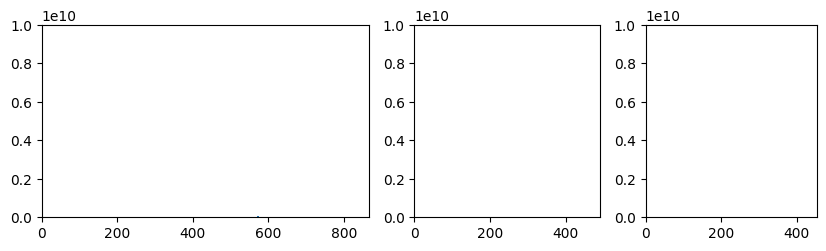

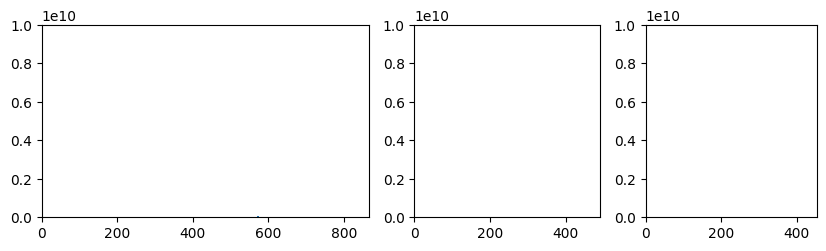

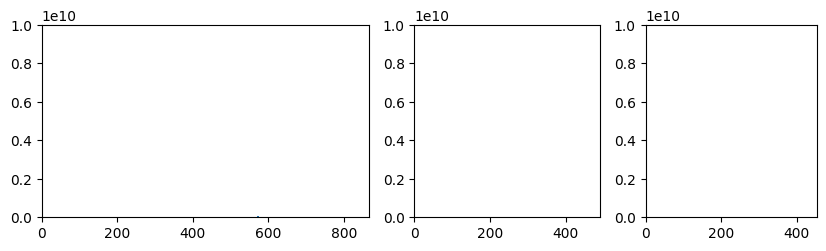

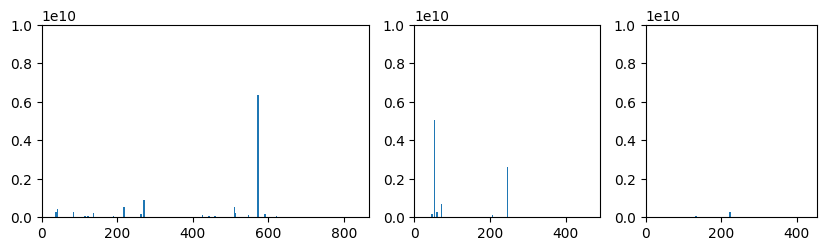

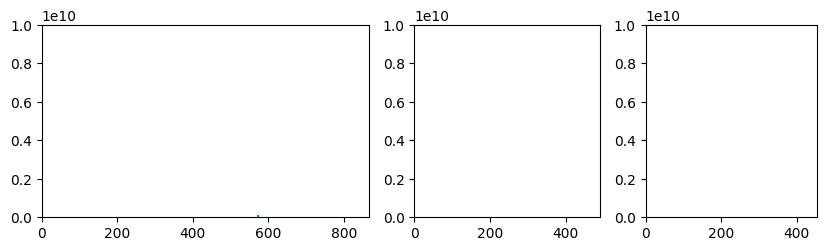

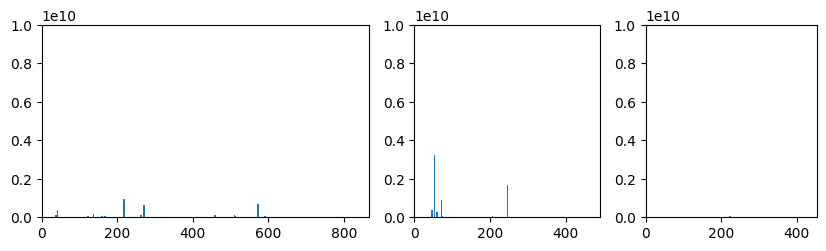

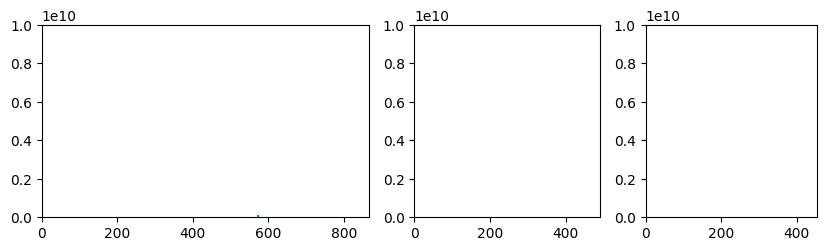

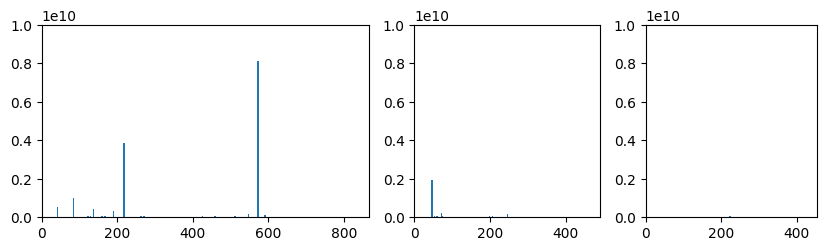

In [16]:
for condition in conditions:

    condition_name = str(condition) +  '_median_normalised'

    fig, axs = plt.subplots(1, 3, figsize=(10,2.5), width_ratios=[866, 491, 453])

    # plot bar chart of median intensities for fibrinogen alpha chain sites
    fib_a_intensity = median_intensity[median_intensity['gene'] == 'FGA']
    x_val = pd.Series(fib_a_intensity['site'])
    y_val = pd.Series(fib_a_intensity[condition_name])
    axs[0].bar(x_val, y_val, width=4)
    axs[0].set_xlim(right = 866, left = 0)
    axs[0].set_ylim(bottom = 0, top = 1 * 10 ** 10)

    # plot bar chart of median intensities for fibrinogen alpha chain sites
    fib_b_intensity = median_intensity[median_intensity['gene'] == 'FGB']
    x_val = pd.Series(fib_b_intensity['site'])
    y_val = pd.Series(fib_b_intensity[condition_name])
    axs[1].bar(x_val, y_val, width=4)
    axs[1].set_xlim(right = 491, left = 0)
    axs[1].set_ylim(bottom = 0, top = 1 * 10 ** 10)

    # plot bar chart of median intensities for fibrinogen alpha chain sites
    fib_g_intensity = median_intensity[median_intensity['gene'] == 'FGG']
    x_val = pd.Series(fib_g_intensity['site'])
    y_val = pd.Series(fib_g_intensity[condition_name])
    axs[2].bar(x_val, y_val, width=4)
    axs[2].set_xlim(right = 453, left = 0)
    axs[2].set_ylim(bottom = 0, top = 1 * 10 ** 10)

    # plt.savefig(f'{condition_name}_all_valid_sites.svg')

